# Понятие эталона. Отступы и классификация объектов качества

Сначала разберём основные понятия. Затем пройдём один пример от начала до конца:
посмотрим на признаки трафика, выберем эталоны, обучим SVM и разберём её ответы.

Для запуска выберите **«Среда выполнения → Выполнить все» / Runtime → Run all**.
Все данные уже здесь. Google Drive, загрузка файлов, GPU и ключи доступа не нужны.
Таблицы и графики сохранены, поэтому их можно посмотреть и без запуска.


## Сначала разберём понятия

### Объект, признаки и класс

**Объектом** называем то, что исследуем. Его измеримые свойства называются
**признаками**. Чтобы сравнивать объекты, описываем их одинаковыми признаками.
**Класс** означает одну из заранее заданных групп.
Когда по признакам выбираем группу объекта, решаем задачу **классификации**.

Правило выбора класса называется **моделью**, или классификатором.
В **обучающей выборке** есть примеры с известными классами, то есть метками.
Во время **обучения** подбираем правило по этим примерам.
Важно различать известную метку и прогноз: модель может ошибиться.

### Эталон и похожесть

**Эталон класса** служит образцом, с которым сравниваем другие объекты.
Есть разные способы его выбрать. Мы возьмём **медоид**:
обучающий объект с наименьшей суммой расстояний до остальных объектов своего класса.
У каждого класса будет свой медоид.

Похожесть измерим евклидовым расстоянием. Чем оно меньше, тем ближе описания объектов.
Сначала приведём признаки к выбранному масштабу. Иначе признак с большими числами
может почти целиком определять расстояние. Выбор масштаба влияет на результат.

После выбора образцов получаем **правило ближайшего эталона**:
считаем расстояния до эталонов и выбираем класс того, который ближе.
Если расстояния равны, нужна заранее заданная договорённость.

### Что показывает отступ

**Отступ** показывает, насколько правило предпочло истинный класс его конкуренту.
Для ближайшего эталона вычитаем расстояние до своего образца из расстояния до чужого.
Свой класс берём из известной метки, а не из прогноза модели.

- Отступ положительный: свой эталон ближе, ответ верен.
- Отступ отрицательный: чужой эталон ближе, правило ошиблось.
- Отступ нулевой: расстояния одинаковы.

Чтобы судить о правильности по знаку, нужно знать истинную метку.
Без неё мы получим прогноз, но ещё не узнаем, верен ли он.

### Как устроена SVM

Одного эталона бывает мало, чтобы описать разнообразие класса.
**Линейная SVM** строит другое правило по всей обучающей выборке.
Если признаков два, её граница выглядит как прямая.
При переходе через **границу решения** меняется прогноз.
Функция решения `f` имеет разные знаки по разные стороны прямой; на границе `f=0`.
Для обучения SVM используем все обучающие объекты, а не только два медоида.

SVM старается оставить вокруг границы широкую полосу. Эта полоса называется **зазором**.
**Мягкий зазор** допускает обучающие точки внутри полосы и даже на ошибочной стороне,
но назначает штраф за такие нарушения. Параметр `C` задаёт цену нарушений.
**Опорные векторы** являются обучающими объектами, которые участвуют в определении границы.

### Отступ SVM и «запас прочности»

**Геометрический отступ SVM со знаком** показывает расстояние до границы и правильность
ответа: плюс означает правильную сторону, минус означает ошибочную.
Для этого знака тоже нужна истинная метка.

Расстояние без знака показывает, насколько нужно изменить масштабированные признаки,
чтобы дойти до границы. Его можно понимать как **запас сохранения текущего ответа**.
Это не вероятность атаки и не гарантия правильности. Даже ошибочный ответ может
быть далеко от границы. Расстояние также не проверяет, можно ли получить такое
изменение признаков в настоящем трафике.

Эталонный отступ `M_ref` и геометрический отступ SVM `γ` устроены по-разному.
**Их величины нельзя напрямую сравнивать.** Разность двух расстояний до образцов
не равна расстоянию до границы SVM.

### Какие объекты стоит перепроверить

**Пограничный объект** находится близко к границе. Небольшое изменение признаков
может сменить прогноз. Рядом с границей бывают объекты обоих классов, верные ответы и ошибки.

Здесь нужны две разные полосы:

- **Зазор SVM** используется при обучении. Его края задаются значениями `f=−1` и `f=+1`.
- **Полосу перепроверки** выбираем уже после обучения. Она помогает выделить ответы,
  которые легко изменятся. Её порог не следует из `C` и не обязан совпадать с зазором.

Теперь применим эти понятия к одной задаче сетевой безопасности.


## Один пример: нормальный трафик и SYN-flood

Обычное TCP-рукопожатие проходит так: **SYN → SYN-ACK → ACK**.
При SYN-flood много начатых подключений остаются незавершёнными.
Занятая очередь может мешать обычным клиентам. Но потери сети и всплеск легитимной
нагрузки тоже могут ухудшать признаки. Поэтому по двум числам не всегда легко отличить атаку.

**Все значения ниже придуманы вручную.** Есть 20 обучающих окон и 8 проверочных.
Проверки специально подобраны, чтобы показать поведение методов, включая ошибки.
Это **не независимая оценка качества** детектора. Процент точности здесь не доказывает,
что сервер защищён.

### Шаг 1. Посмотрим на признаки

Один объект содержит трафик за **10 секунд к одному IP и TCP-порту**.

- `SYN/с` показывает среднюю частоту входящих SYN-пакетов за окно. Повторы тоже входят в счётчик.
- `Без рукопожатия, %` показывает долю начатых попыток, у которых полное рукопожатие
  не завершилось за 3 секунды. Повторы одной попытки объединяем.

Нужно видеть оба направления трафика и дождаться тайм-аута последней попытки.
Окна без SYN-попыток исключаем, потому что доля для них не определена.
Эта учебная модель принимает только положительный `SYN/с`.

Автор задал метки: `−1` для нормы, `+1` для SYN-flood. Начнём с библиотек.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.svm import SVC
from IPython.display import display

label_ru = {-1: "Норма", 1: "SYN-flood"}
pd.set_option("display.max_columns", 12)
print("Данные встроены; внешние файлы не нужны.")


Данные встроены; внешние файлы не нужны.


В обучающей таблице 20 окон: по 10 каждого класса.
Только по ним выберем эталоны и обучим SVM.


In [2]:
train_raw = pd.DataFrame([
    ['N01', 200, 5.0, -1], ['N02', 320, 8.0, -1],
    ['N03', 450, 10.0, -1], ['N04', 550, 8.0, -1],
    ['N05', 600, 15.0, -1], ['N06', 720, 12.0, -1],
    ['N07', 850, 18.0, -1], ['N08', 1050, 15.0, -1],
    ['N09', 920, 30.0, -1], ['N10', 750, 40.0, -1],
    ['A01', 1050, 65.0, 1], ['A02', 1200, 75.0, 1],
    ['A03', 1400, 82.0, 1], ['A04', 1600, 90.0, 1],
    ['A05', 1800, 92.0, 1], ['A06', 1300, 65.0, 1],
    ['A07', 1500, 75.0, 1], ['A08', 950, 60.0, 1],
    ['A09', 1100, 50.0, 1], ['A10', 800, 56.0, 1],
], columns=["ID", "SYN/с", "Без рукопожатия, %", "y"])
display(train_raw.assign(Класс=train_raw["y"].map(label_ru)).drop(columns="y"))


,ID,SYN/с,"Без рукопожатия, %",Класс
0,N01,200,5.0,Норма
1,N02,320,8.0,Норма
2,N03,450,10.0,Норма
3,N04,550,8.0,Норма
4,N05,600,15.0,Норма
5,N06,720,12.0,Норма
6,N07,850,18.0,Норма
7,N08,1050,15.0,Норма
8,N09,920,30.0,Норма
9,N10,750,40.0,Норма


Следующие восемь окон не участвуют в выборе эталонов и обучении.
На них посмотрим, как работают готовые правила.
Одно окно, **T07**, проведём через оба метода с теми же признаками и меткой.


In [3]:
check_raw = pd.DataFrame([
    ['T01', 420, 9.0, -1], ['T02', 1550, 88.0, 1],
    ['T03', 950, 40.0, -1], ['T04', 900, 40.0, 1],
    ['T05', 1000, 42.0, -1], ['T06', 950, 46.0, 1],
    ['T07', 1200, 16.0, -1], ['T08', 950, 75.0, 1],
], columns=["ID", "SYN/с", "Без рукопожатия, %", "y"])
display(check_raw.assign(Класс=check_raw["y"].map(label_ru)).drop(columns="y"))


,ID,SYN/с,"Без рукопожатия, %",Класс
0,T01,420,9.0,Норма
1,T02,1550,88.0,SYN-flood
2,T03,950,40.0,Норма
3,T04,900,40.0,SYN-flood
4,T05,1000,42.0,Норма
5,T06,950,46.0,SYN-flood
6,T07,1200,16.0,Норма
7,T08,950,75.0,SYN-flood


### Шаг 2. Выберем масштаб

Делим частоту на 1000, а проценты на 100.
T07 с `1200 SYN/с` и `16%` превращается в `(1.20; 0.16)`.
Этот учебный масштаб задан заранее. Мы не подбираем его по проверочным меткам
и дальше используем без изменений.


In [4]:
feature_names = ["SYN/с", "Без рукопожатия, %"]
feature_scale = np.array([1000.0, 100.0])
X_train = train_raw[feature_names].to_numpy(dtype=float) / feature_scale
X_check = check_raw[feature_names].to_numpy(dtype=float) / feature_scale
y_train = train_raw["y"].to_numpy()
y_check = check_raw["y"].to_numpy()
t07_index = int(np.flatnonzero(check_raw["ID"].to_numpy() == "T07")[0])
print("T07 после масштабирования:", X_check[t07_index])


T07 после масштабирования: [1.2  0.16]


### Шаг 3. Найдём по одному медоиду в каждом классе

Для каждого кандидата сложим расстояния до остальных обучающих точек своего класса.
Выберем наименьшую сумму. Если суммы совпадут, возьмём меньший ID.
Функция ниже выполняет эти шаги.


In [5]:
def choose_medoid(points, ids):
    distances = np.linalg.norm(points[:, None, :] - points[None, :, :], axis=2)
    sums = distances.sum(axis=1)
    tied = np.flatnonzero(np.isclose(sums, sums.min(), rtol=0, atol=1e-12))
    best = min(tied, key=lambda index: ids[index])
    return ids[best], points[best].copy(), float(sums[best]), sums

prototypes, candidate_rows, selected_rows = {}, [], []
for label in [-1, 1]:
    mask = y_train == label
    ids = train_raw.loc[mask, "ID"].to_numpy()
    ident, point, total, sums = choose_medoid(X_train[mask], ids)
    prototypes[label] = point
    selected_rows.append([label_ru[label], ident, *point, total])
    candidate_rows.extend([[label_ru[label], i, s] for i, s in zip(ids, sums)])
display(pd.DataFrame(selected_rows, columns=["Класс", "Медоид", "x1", "x2", "Минимальная сумма"]).round(6))


,Класс,Медоид,x1,x2,Минимальная сумма
0,Норма,N05,0.6,0.15,2.415511
1,SYN-flood,A06,1.3,0.65,2.882603


Для нормы выбран **N05 с 600 SYN/с и 15%**, для атаки **A06 с 1300 SYN/с и 65%**.
Это образцы нашей таблицы, а не универсальные пороги атаки.
Суммы для всех кандидатов сохранены в `candidate_rows`. Их можно посмотреть в дополнении.

### Шаг 4. Сравним T07 с эталонами

У T07 **1200 SYN/с и 16%**. В учебной таблице его истинный класс указан как норма.
Поэтому для него свой эталон принадлежит норме, а чужой принадлежит атаке.


In [6]:
d_normal = np.linalg.norm(X_check - prototypes[-1], axis=1)
d_attack = np.linalg.norm(X_check - prototypes[1], axis=1)
score_difference = d_normal - d_attack
score_difference[np.isclose(score_difference, 0, rtol=0, atol=1e-12)] = 0
prototype_prediction = np.where(score_difference > 0, 1, -1)
margin_ref = y_check * score_difference
print(f"T07: до нормы {d_normal[t07_index]:.6f}; до атаки {d_attack[t07_index]:.6f}")
print("Прогноз по эталону:", label_ru[prototype_prediction[t07_index]])
print(f"Отступ чужой−свой: {d_attack[t07_index]:.6f} − {d_normal[t07_index]:.6f} = {margin_ref[t07_index]:.6f}")


T07: до нормы 0.600083; до атаки 0.500100
Прогноз по эталону: SYN-flood
Отступ чужой−свой: 0.500100 − 0.600083 = -0.099983


Эталон атаки оказался ближе. **Правило ошиблось**, поэтому отступ отрицательный.
Так высокая легитимная нагрузка показывает слабое место описания класса одним образцом.

При равных расстояниях код выбирает норму. Такая ситуация есть у T03.
Равенство стоит отметить отдельно и разобраться с объектом.

### Шаг 5. Обучим SVM на всех 20 окнах

Берём ту же выборку и тот же масштаб. Для SVM используем все обучающие точки,
не только медоиды. Параметр `C=1` фиксируем для примера, без подбора по проверкам.


In [7]:
model = SVC(kernel="linear", C=1.0, tol=1e-10, shrinking=False)
model.fit(X_train, y_train)
w = model.coef_[0]
b = float(model.intercept_[0])
norm_w = float(np.linalg.norm(w))
print(f"Коэффициенты: w={w.round(6)}, b={b:.6f}")
print("Обучающих окон:", len(X_train), "; опорных векторов:", len(model.support_))


Коэффициенты: w=[1.216667 2.116667], b=-2.047500
Обучающих окон: 20 ; опорных векторов: 12


### Шаг 6. Проверим то же T07 с помощью SVM

Измерения и метка T07 остаются прежними. Получим прогноз, значение функции `f`,
геометрический отступ со знаком `γ` и расстояние без знака `r`.
Формулы собраны в дополнении в конце.


In [8]:
prediction = model.predict(X_check)
f = model.decision_function(X_check)
m = y_check * f
gamma = m / norm_w
r = np.abs(f) / norm_w
print("T07, прогноз SVM:", label_ru[prediction[t07_index]])
print(f"f={f[t07_index]:+.6f}; γ={gamma[t07_index]:+.6f}; r={r[t07_index]:.6f}")


T07, прогноз SVM: Норма
f=-0.248833; γ=+0.101921; r=0.101921


Теперь SVM выбрала **норму**, и это совпало с известной меткой.
Плюс у `γ ≈ 0.101921` означает правильную сторону границы.
Число `r ≈ 0.101921` показывает запас текущего ответа в выбранном масштабе.

Не сравниваем `−0.099983` у эталонов и `+0.101921` у SVM как одну величину.
Определения отступов разные. В этом примере SVM исправила ошибку,
но **один удачный случай не доказывает, что она всегда лучше**.

На первом графике посмотрим на обучение. Здесь только 20 обучающих точек,
опорные векторы и зазор между `f=−1` и `f=+1`. Проверочных окон на нём нет.


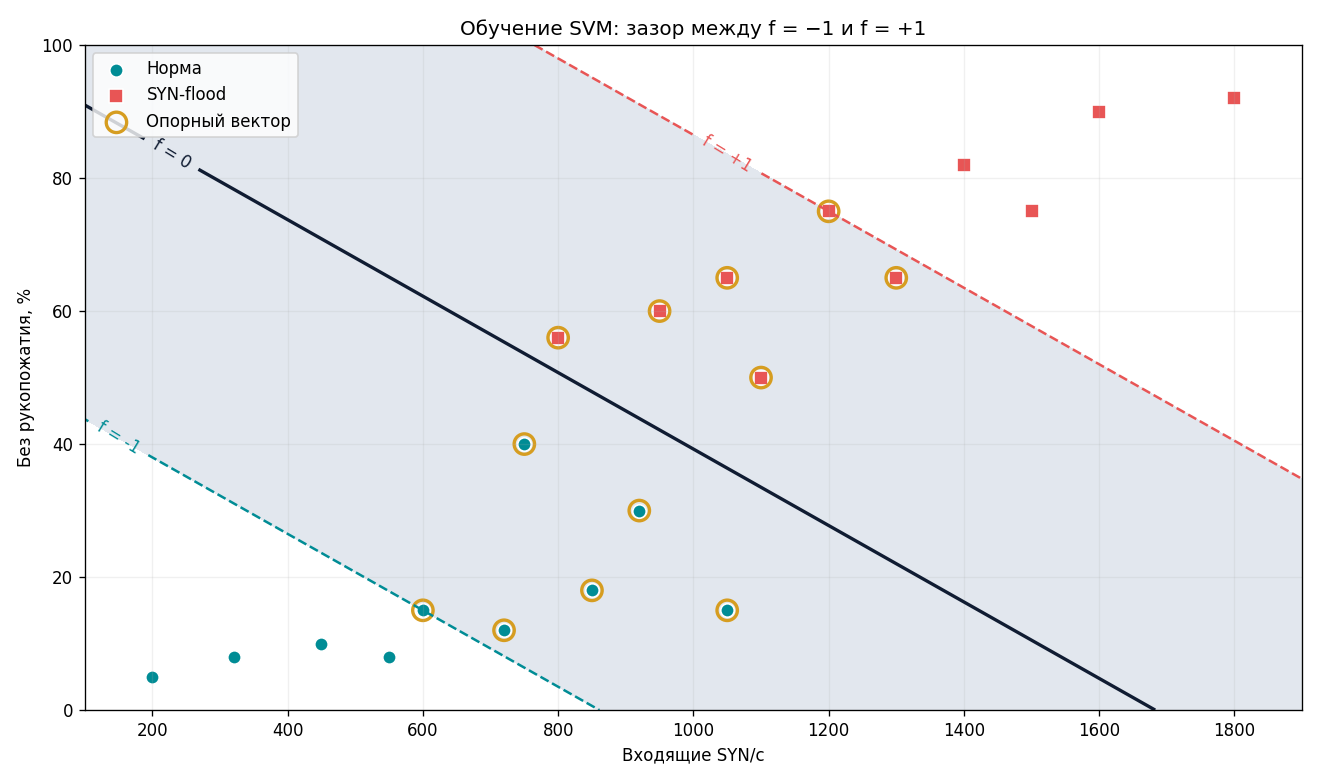

In [9]:
grid_syn, grid_percent = np.meshgrid(np.linspace(100, 1900, 400), np.linspace(0, 100, 300))
grid_features = np.column_stack([grid_syn.ravel(), grid_percent.ravel()]) / feature_scale
grid_f = model.decision_function(grid_features).reshape(grid_syn.shape)
blue, red, ink, grey, gold = "#008C95", "#E85555", "#101C32", "#CBD5E1", "#D69D20"
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.contourf(grid_syn, grid_percent, grid_f, levels=[-1, 1], colors=[grey], alpha=0.55)
lines = ax.contour(grid_syn, grid_percent, grid_f, levels=[-1, 0, 1], colors=[blue, ink, red],
                   linestyles=["--", "-", "--"], linewidths=[1.5, 2, 1.5])
ax.clabel(lines, fmt={-1: "f = -1", 0: "f = 0", 1: "f = +1"}, fontsize=10)
for label, marker, color in [(-1, "o", blue), (1, "s", red)]:
    mask = y_train == label
    ax.scatter(train_raw.loc[mask, "SYN/с"], train_raw.loc[mask, "Без рукопожатия, %"],
               marker=marker, c=color, s=65, edgecolor="white", label=label_ru[label])
support_raw = train_raw.iloc[model.support_]
ax.scatter(support_raw["SYN/с"], support_raw["Без рукопожатия, %"], s=150,
           facecolor="none", edgecolor=gold, linewidth=2, label="Опорный вектор")
ax.set(xlim=(100, 1900), ylim=(0, 100), xlabel="Входящие SYN/с", ylabel="Без рукопожатия, %",
       title="Обучение SVM: зазор между f = −1 и f = +1")
ax.grid(alpha=0.18)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


### Шаг 7. Посчитаем результаты для всех восьми окон

Для этой таблицы известны истинные метки. Поэтому можно проверить прогнозы
и посчитать отступы со знаком. У нового объекта без метки мы ещё не знаем,
правильный ли ответ дала модель.


In [10]:
all_checks = pd.DataFrame({"ID": check_raw["ID"],
    "Истинный класс": [label_ru[y] for y in y_check],
    "Прогноз SVM": [label_ru[y] for y in prediction],
    "f": f, "m = y*f": m, "γ": gamma, "r": r, "M_ref": margin_ref})
display(all_checks.round(6))


,ID,Истинный класс,Прогноз SVM,f,m = y*f,γ,r,M_ref
0,T01,Норма,Норма,-1.346000,1.346000,0.551317,0.551317,0.853336
1,T02,SYN-flood,SYN-flood,1.701000,1.701000,0.696724,0.696724,0.858376
2,T03,Норма,Норма,-0.045000,0.045000,0.018432,0.018432,-0.000000
3,T04,SYN-flood,Норма,-0.105833,-0.105833,-0.043349,0.043349,-0.081187
4,T05,Норма,SYN-flood,0.058167,-0.058167,-0.023825,0.023825,-0.104576
5,T06,SYN-flood,SYN-flood,0.082000,0.082000,0.033587,0.033587,0.069301
6,T07,Норма,Норма,-0.248833,0.248833,0.101921,0.101921,-0.099983
7,T08,SYN-flood,SYN-flood,0.695833,0.695833,0.285011,0.285011,0.330617


### Шаг 8. Найдём окна с малым запасом

Для примера отправим на перепроверку окна с **r < 0.10**.
Этот порог выбираем после обучения. Он не равен зазору SVM и сам по себе
не служит правилом обнаружения атаки.


In [11]:
TAU = 0.10
boundary_review = r < TAU
print("Пограничные окна:", ", ".join(check_raw.loc[boundary_review, "ID"]))
error_mask = prediction != y_check
error_table = all_checks.loc[error_mask, ["ID", "Истинный класс", "Прогноз SVM", "γ", "r"]].copy()
error_table["Тип ошибки"] = ["Пропуск атаки" if y == 1 else "Ложная тревога" for y in y_check[error_mask]]
display(error_table.round(6))


,ID,Истинный класс,Прогноз SVM,γ,r,Тип ошибки
3,T04,SYN-flood,Норма,-0.043349,0.043349,Пропуск атаки
4,T05,Норма,SYN-flood,-0.023825,0.023825,Ложная тревога


Пограничные окна: T03, T04, T05, T06


На перепроверку попали **T03, T04, T05 и T06**.
T03 и T06 модель распознала верно. В двух других случаях она ошиблась:

- **T04** содержит атаку, но модель выбрала норму. Это пропуск атаки.
- **T05** относится к норме, но модель выбрала атаку. Это ложная тревога.

Обе ошибки здесь оказались рядом с границей. В настоящей сети так бывает не всегда.
T07 с `r ≈ 0.101921` находится совсем рядом с выбранным порогом, но уже за полосой.
Сам порог 0.10 не создаёт гарантии правильности.

### Как читать следующий график

По горизонтали отложена частота **SYN/с**, по вертикали процент **незавершённых попыток**.
Цвет показывает известный класс из таблицы: бирюзовый для нормы, красный для атаки.

Чёрная линия отделяет ответы SVM. **Выше линии модель выбирает атаку, ниже норму.**
Серая полоса содержит окна с `r < 0.10`. В ней небольшое изменение признаков может
сменить прогноз. Расстояние `r` при этом считается в том масштабе, который выбрали ранее.

Красная T04 лежит на стороне нормы, а бирюзовая T05 на стороне атаки.
Стрелки помогают найти эти две ошибки. T07 находится на стороне нормы,
поэтому SVM распознала его верно.

На этом графике серая полоса означает **перепроверку**, а не зазор обучения `f=±1`.


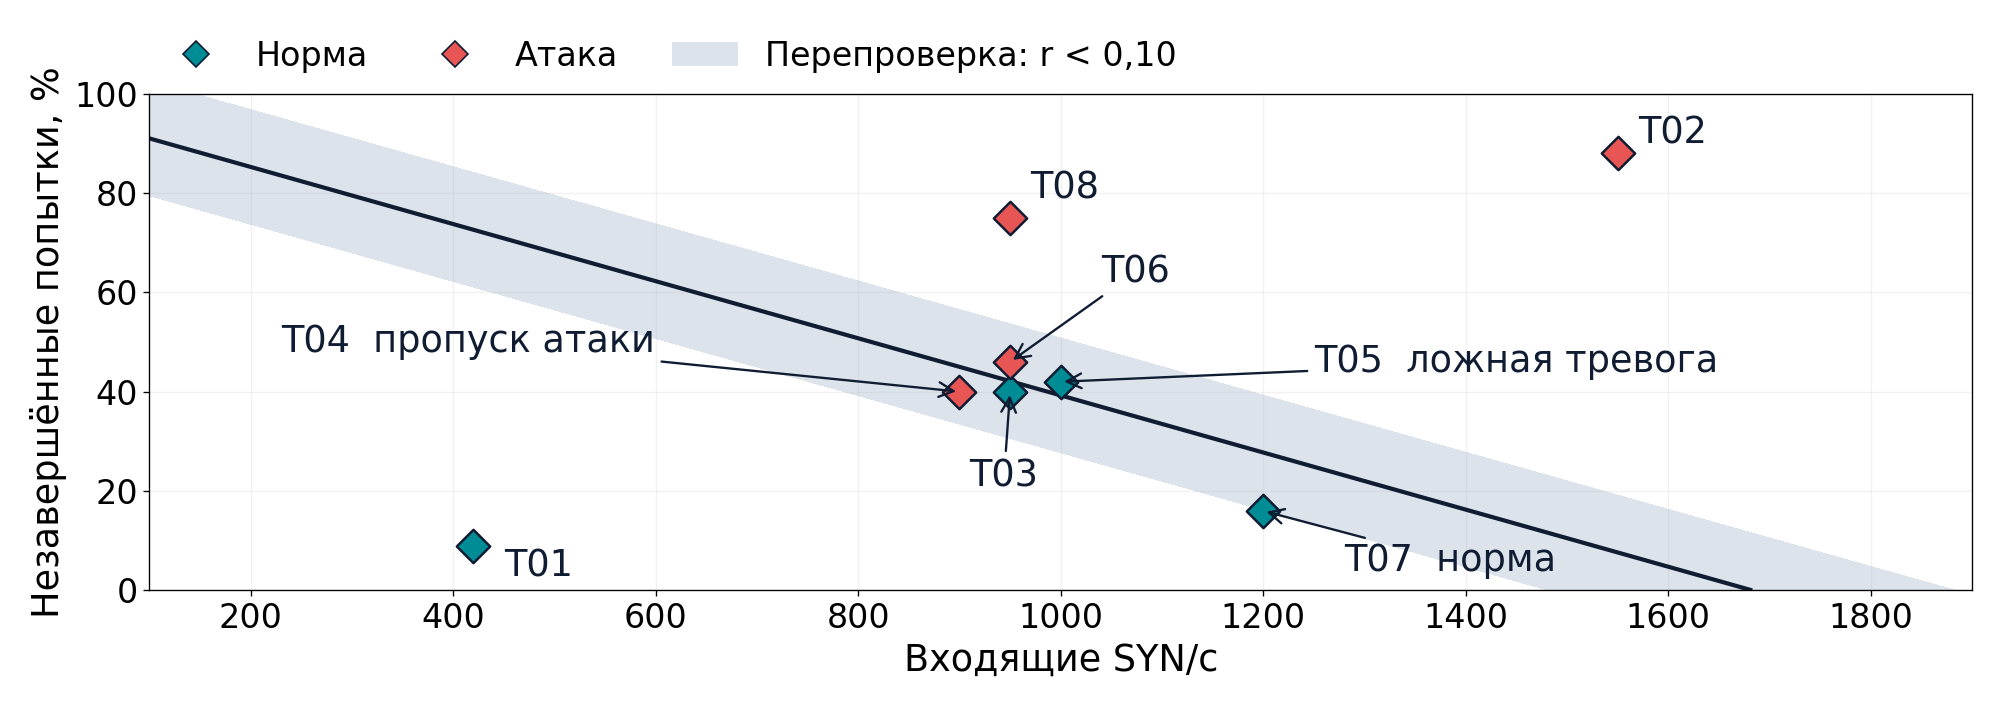

In [12]:
grid_r = np.abs(grid_f) / norm_w
fig, ax = plt.subplots(figsize=(16.6, 6))
fig.subplots_adjust(left=0.075, right=0.99, bottom=0.18, top=0.87)
ax.contourf(grid_syn, grid_percent, grid_r, levels=[0, TAU], colors=[grey], alpha=0.65)
ax.contour(grid_syn, grid_percent, grid_f, levels=[0], colors=[ink], linewidths=2.5)
for index, row in check_raw.iterrows():
    color = blue if row["y"] == -1 else red
    ax.scatter(row["SYN/с"], row["Без рукопожатия, %"], marker="D", c=color,
               s=200, edgecolor=ink, linewidth=1.5, zorder=4)
labels = {"T01": (450, 5), "T02": (1570, 92), "T08": (970, 81)}
for ident, position in labels.items():
    ax.text(*position, ident, fontsize=22, color=ink, va="center")
callouts = [("T03", "T03", (910, 23)), ("T06", "T06", (1040, 64)),
            ("T04", "T04  пропуск атаки", (230, 50)),
            ("T05", "T05  ложная тревога", (1250, 46)),
            ("T07", "T07  норма", (1280, 6))]
for ident, label, position in callouts:
    row = check_raw.loc[check_raw["ID"] == ident].iloc[0]
    ax.annotate(label, (row["SYN/с"], row["Без рукопожатия, %"]), xytext=position,
                fontsize=22, color=ink, va="center",
                arrowprops={"arrowstyle": "->", "color": ink, "lw": 1.4}, zorder=5)
handles = [Line2D([], [], marker="D", color="none", markerfacecolor=c,
                  markeredgecolor=ink, markersize=11, label=label)
           for label, c in [("Норма", blue), ("Атака", red)]]
handles.append(Patch(facecolor=grey, alpha=0.65, label="Перепроверка: r < 0,10"))
ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.015), ncol=3,
          frameon=False, fontsize=20, borderaxespad=0, columnspacing=1.6)
ax.set_xlim(100, 1900)
ax.set_ylim(0, 100)
ax.set_xlabel("Входящие SYN/с", fontsize=22)
ax.set_ylabel("Незавершённые попытки, %", fontsize=22)
ax.tick_params(labelsize=20)
ax.grid(alpha=0.16)
plt.show()


### Шаг 9. Передадим ответ аналитику ИБ

SOC называют команду мониторинга и реагирования на события ИБ.
В нашей функции будут два отдельных флага:

- `attack_alert` включается, когда модель выбирает атаку, даже далеко от границы.
- `boundary_review` включается при малом запасе, какой бы класс ни выбрала модель.

Близость к границе помогает собрать очередь пограничных случаев.
Она не заменяет очередь алертов и не показывает общий риск инцидента.

Функция принимает SYN/с и проценты, применяет прежний масштаб и даёт рекомендацию.
Истинной метки у неё нет. **Функция не блокирует трафик и не меняет настройки сети.**


In [13]:
def triage(syn_per_second, unfinished_percent):
    values = np.array([syn_per_second, unfinished_percent], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Нужны конечные числовые значения.")
    if values[0] <= 0:
        raise ValueError("Для классификации нужен положительный SYN/с; окна без попыток исключаем")
    if not 0 <= values[1] <= 100:
        raise ValueError("Доля незавершённых рукопожатий должна быть от 0 до 100%.")
    features = values.reshape(1, -1) / feature_scale
    predicted = int(model.predict(features)[0])
    distance = abs(float(model.decision_function(features)[0])) / norm_w
    alert, review = predicted == 1, bool(distance < TAU)
    action = ("Алерт + перепроверка" if review else "Алерт") if alert else ("Перепроверка" if review else "Наблюдение")
    return {"predicted_class": label_ru[predicted], "attack_alert": alert,
            "boundary_review": review, "r": round(distance, 6), "action": action}


В пяти вызовах ниже есть только измерения и ответы функции, без истинных меток.
Сравните два случая. Для `(900, 40)` получаем норму с перепроверкой,
а для `(1550, 88)` алерт атаки без пограничной перепроверки.


In [14]:
demo_inputs = [(420, 9), (1550, 88), (950, 40), (900, 40), (1000, 42)]
demo_rows = [{"SYN/с": syn, "Без рукопожатия, %": percent, **triage(syn, percent)}
             for syn, percent in demo_inputs]
display(pd.DataFrame(demo_rows))


,SYN/с,"Без рукопожатия, %",predicted_class,attack_alert,boundary_review,r,action
0,420,9,Норма,False,False,0.551317,Наблюдение
1,1550,88,SYN-flood,True,False,0.696724,Алерт
2,950,40,Норма,False,True,0.018432,Перепроверка
3,900,40,Норма,False,True,0.043349,Перепроверка
4,1000,42,SYN-flood,True,True,0.023825,Алерт + перепроверка


После сигнала аналитик проверяет логи, доступность сервиса, очередь соединений,
потери и обычную нагрузку. Для рабочей системы понадобятся реальные данные,
проверка на более поздних периодах, оценка пропусков и ложных тревог,
дополнительные признаки и правила реагирования.
Этот пример ещё не доказывает готовность к работе в сети.

Мы прошли весь путь на одних данных: измерили признаки, выбрали масштаб и эталоны,
проверили T07 двумя способами, разобрали восемь ответов и отделили алерт от перепроверки.


## Дополнение с формулами

Этот раздел можно пропустить при первом чтении.

| Величина | Как её считаем и что она означает |
|---|---|
| `M_ref` | Расстояние до чужого эталона минус расстояние до своего |
| `f = w₁x₁ + w₂x₂ + b` | Функция SVM: минус выбирает норму, плюс выбирает атаку |
| `m = y*f` | Функциональный отступ со знаком правильности |
| `γ = y*f / ‖w‖` | Геометрический отступ SVM со знаком правильности |
| `r = abs(f) / ‖w‖ = abs(γ)` | Расстояние до границы в выбранном масштабе |
| `max(0, 1−m)` | Hinge loss, то есть штраф за недостаточный отступ |
| `2 / ‖w‖` | Ширина полосы обучения между `f=−1` и `f=+1` |

Используем `y=−1` для нормы и `y=+1` для атаки.
Чтобы судить о правильности по знаку `m`, `γ` или `M_ref`, нужна известная метка.
Прогноз и расстояние `r` можно получить без неё.

`M_ref` не является расстоянием до границы SVM. Поэтому его величину нельзя напрямую
сравнивать с `γ`. На обучающих точках минимальная slack-переменная равна `max(0, 1−m)`.
На проверках это hinge loss для разбора ответа, а не переменная уже решённой задачи обучения.
Опорными векторами могут быть только обучающие точки.


In [15]:
details = all_checks.copy()
details["hinge = max(0, 1-m)"] = np.maximum(0, 1-m)
display(details.round(6))
print(f"‖w‖ = {norm_w:.9f}; ширина обучения 2/‖w‖ = {2/norm_w:.9f}")
print("Опорные ID:", ", ".join(train_raw.iloc[model.support_]["ID"]))
display(pd.DataFrame(candidate_rows, columns=["Класс", "Кандидат", "Сумма расстояний"]).round(6))


,ID,Истинный класс,Прогноз SVM,f,m = y*f,γ,r,M_ref,"hinge = max(0, 1-m)"
0,T01,Норма,Норма,-1.346000,1.346000,0.551317,0.551317,0.853336,0.000000
1,T02,SYN-flood,SYN-flood,1.701000,1.701000,0.696724,0.696724,0.858376,0.000000
2,T03,Норма,Норма,-0.045000,0.045000,0.018432,0.018432,-0.000000,0.955000
3,T04,SYN-flood,Норма,-0.105833,-0.105833,-0.043349,0.043349,-0.081187,1.105833
4,T05,Норма,SYN-flood,0.058167,-0.058167,-0.023825,0.023825,-0.104576,1.058167
5,T06,SYN-flood,SYN-flood,0.082000,0.082000,0.033587,0.033587,0.069301,0.918000
6,T07,Норма,Норма,-0.248833,0.248833,0.101921,0.101921,-0.099983,0.751167
7,T08,SYN-flood,SYN-flood,0.695833,0.695833,0.285011,0.285011,0.330617,0.304167


,Класс,Кандидат,Сумма расстояний
0,Норма,N01,4.599751
1,Норма,N02,3.623601
2,Норма,N03,2.862364
3,Норма,N04,2.572858
4,Норма,N05,2.415511
5,Норма,N06,2.520975
6,Норма,N07,2.904168
7,Норма,N08,4.268772
8,Норма,N09,3.499612
9,Норма,N10,3.392102


‖w‖ = 2.441425022; ширина обучения 2/‖w‖ = 0.819193701
Опорные ID: N05, N06, N07, N08, N09, N10, A01, A02, A06, A08, A09, A10


### Задача обучения с мягким зазором

$$\min_{w,b,\xi}\; \frac{1}{2}\lVert w\rVert^2 + C\sum_i\xi_i.$$

$$y_i(w^\mathsf{T}x_i+b)\ge 1-\xi_i,\qquad \xi_i\ge 0.$$

Параметр `C` задаёт цену нарушения отступа. При большем `C` штраф сильнее.
Полоса обучения задаётся значениями `f=±1`.
Порог перепроверки `r<0.10` выбираем отдельно.

### Где почитать подробнее

- [scikit-learn: SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [scikit-learn: support vector machines](https://scikit-learn.org/stable/modules/svm.html)
- [RFC 4987: TCP SYN Flooding Attacks and Common Mitigations](https://www.rfc-editor.org/rfc/rfc4987)

Эти источники объясняют метод и атаку. Числа ноутбука придуманы для учебного примера,
они не взяты из перечисленных источников.
